# 01 – Dữ liệu: thống kê mô tả

**Người phụ trách:** Phúc · **Đầu vào:** `data/processed/articles.csv` (nếu chưa có thì dùng `articles_sample.csv`) · **Đầu ra:** `outputs/figures/eda_so_bai_chu_de.png`, `eda_do_dai.png`, và các bảng số liệu để điền `ket_qua/01_du_lieu.md`.

Cách dùng: **Restart kernel → Run All** (chạy từ trên xuống). Sau khi có `articles.csv` chính thức, chạy lại toàn bộ rồi commit notebook **kèm output**.

In [1]:
import sys; sys.path.append("..")
from src.config import *

In [2]:
import json
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.preprocess import load_articles, get_tokens

USE_SAMPLE = not ARTICLES_CSV.exists()  # chưa có articles.csv thì dùng dữ liệu mẫu
df = load_articles(sample=USE_SAMPLE)
print("Đang dùng:", "articles_sample.csv (DỮ LIỆU MẪU)" if USE_SAMPLE else "articles.csv (dữ liệu chính thức)")
print("Số bài:", len(df))

# tên hiển thị của các báo (chỉ dùng để vẽ hình và in bảng)
source_names = {"vnexpress": "VnExpress", "tuoitre": "Tuổi Trẻ", "thanhnien": "Thanh Niên", "dantri": "Dân trí"}
df[["id", "title", "source", "true_label"]].head(5)

Đang dùng: articles.csv (dữ liệu chính thức)
Số bài: 1800


,id,title,source,true_label
0,doc_0001,Hà Nội chốt hạn di dời cư dân tại 12 dự án Mườ...,vnexpress,thoi_su
1,doc_0002,"Công thức 3-2-1 giúp Jessica Alba siết mỡ, giữ...",vnexpress,suc_khoe
2,doc_0003,Grab hợp tác Sovico thúc đẩy phát triển bền vững,vnexpress,kinh_te
3,doc_0004,Đánh giá Vivo X500 Pro Max - smartphone cho ch...,vnexpress,cong_nghe
4,doc_0005,Alcaraz hủy diệt đối thủ ở ATP Finals,vnexpress,the_thao


## 1. Kiểm tra chất lượng dữ liệu

Mỗi dòng phải là ✔. Dòng nào ✘ thì sửa trong `src/crawl.py` hoặc `src/preprocess.py` rồi tạo lại `articles.csv`.

In [3]:
text_cols = ["title", "content", "text_tok", "text_bert", "text_bert_seg"]  # sapo được phép trống (text_bert khi đó chỉ có tiêu đề)
checks = {
    "Đủ 11 cột, đúng thứ tự (ARTICLE_COLUMNS)": list(df.columns) == ARTICLE_COLUMNS,
    "id không trùng": df["id"].is_unique,
    "url không trùng": df["url"].is_unique,
    "title không trùng": df["title"].is_unique,
    "true_label thuộc 6 chủ đề (TOPICS)": bool(df["true_label"].isin(TOPICS).all()),
    "source thuộc 4 báo (SOURCES)": bool(df["source"].isin(SOURCES).all()),
    "Các cột văn bản (trừ sapo) không có ô trống": bool((df[text_cols] != "").all().all()),
    "date đúng dạng YYYY-MM-DD": bool(df["date"].str.match(r"^\d{4}-\d{2}-\d{2}$").all()),
    f"Mọi bài có từ {MIN_WORDS} từ trở lên": bool((df["content"].str.split().str.len() >= MIN_WORDS).all()),
}
for name, ok in checks.items():
    print("✔" if ok else "✘", name)

print(f"ℹ Số bài không có sapo: {(df['sapo'] == '').sum()} (chấp nhận được)")

counts = df["true_label"].value_counts().reindex(list(TOPICS), fill_value=0)
gap = (counts.max() - counts.min()) / counts.max()
print()
print(f"Số bài mỗi chủ đề: nhỏ nhất {counts.min()}, lớn nhất {counts.max()}, chênh lệch {gap:.1%}",
      "✔ (≤ 10%)" if gap <= 0.10 else "✘ (> 10%, cần cân bằng lại)")
print(f"Mỗi chủ đề ≥ {MIN_ARTICLES_PER_TOPIC} bài:", "✔" if counts.min() >= MIN_ARTICLES_PER_TOPIC else "✘ (cần crawl thêm)")

✔ Đủ 11 cột, đúng thứ tự (ARTICLE_COLUMNS)
✔ id không trùng
✔ url không trùng
✔ title không trùng
✔ true_label thuộc 6 chủ đề (TOPICS)
✔ source thuộc 4 báo (SOURCES)
✔ Các cột văn bản (trừ sapo) không có ô trống
✔ date đúng dạng YYYY-MM-DD
✔ Mọi bài có từ 150 từ trở lên
ℹ Số bài không có sapo: 1 (chấp nhận được)

Số bài mỗi chủ đề: nhỏ nhất 300, lớn nhất 300, chênh lệch 0.0% ✔ (≤ 10%)
Mỗi chủ đề ≥ 200 bài: ✔


## 2. Số bài theo chủ đề và nguồn báo

In [4]:
table = pd.crosstab(df["true_label"], df["source"]).reindex(index=list(TOPICS), columns=SOURCES, fill_value=0)
table["Tổng"] = table.sum(axis=1)
table.loc["Tổng"] = table.sum()
table.index = [TOPICS.get(k, k) for k in table.index]
table.columns = [source_names.get(c, c) for c in table.columns]
table

,VnExpress,Tuổi Trẻ,Thanh Niên,Dân trí,Tổng
Thời sự,108,20,63,109,300
Kinh tế,117,15,51,117,300
Thể thao,107,38,47,108,300
Giải trí,111,18,59,112,300
Công nghệ,107,34,52,107,300
Sức khỏe,108,22,62,108,300
Tổng,658,147,334,661,1800


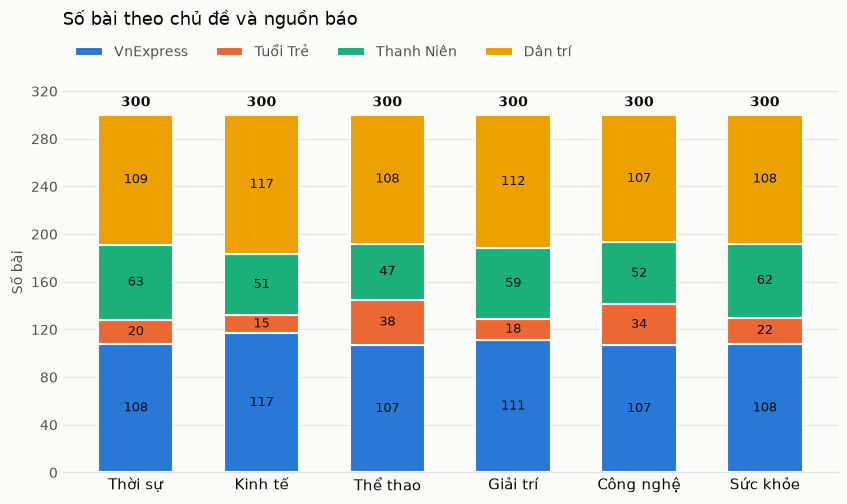

In [5]:
# Hình 1: số bài theo chủ đề, chia theo nguồn báo
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # bảng màu đã kiểm tra, đúng thứ tự

plot = pd.crosstab(df["true_label"], df["source"]).reindex(index=list(TOPICS), columns=SOURCES, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
bottom = pd.Series(0, index=plot.index)
for color, src in zip(SERIES, SOURCES):
    ax.bar(range(len(plot)), plot[src], bottom=bottom, width=0.6, color=color,
           edgecolor=SURFACE, linewidth=1.5, label=source_names[src])
    for i, (v, b) in enumerate(zip(plot[src], bottom)):  # số bài trong từng đoạn cột
        if v > 0:
            ax.text(i, b + v / 2, int(v), ha="center", va="center", fontsize=9, color=INK)
    bottom = bottom + plot[src]
for i, total in enumerate(bottom):  # tổng trên đầu cột
    ax.text(i, total + bottom.max() * 0.015, int(total), ha="center", va="bottom", fontsize=10, color=INK, fontweight="bold")
ax.set_xticks(range(len(plot)))
ax.set_xticklabels([TOPICS[k] for k in plot.index], color=INK, fontsize=11)
ax.set_ylim(0, bottom.max() * 1.12)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("Số bài", color=INK2)
ax.tick_params(axis="y", colors=INK2, length=0)
ax.tick_params(axis="x", length=0)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.set_title("Số bài theo chủ đề và nguồn báo", loc="left", fontsize=13, color=INK, pad=34)
ax.legend(ncol=4, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK2)
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "eda_so_bai_chu_de.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## 3. Độ dài văn bản

- `content`: toàn văn bài báo (nguồn để tạo `text_tok`).
- `text_bert`: tiêu đề + sapo, đưa vào BERT (giới hạn `MAX_LENGTH` token nên không nên quá dài).
- `text_tok`: toàn văn đã chữ thường, tách từ, bỏ stopwords, đưa vào LDA/LSA.

In [6]:
df["n_content"] = df["content"].str.split().str.len()
df["n_bert"] = df["text_bert"].str.split().str.len()
df["n_tok"] = df["text_tok"].str.split().str.len()

length_stats = df[["n_content", "n_bert", "n_tok"]].agg(["mean", "median", "min", "max", "std"]).T.round(1)
length_stats.index = ["content (toàn văn)", "text_bert (tiêu đề + sapo)", "text_tok (đã tách từ, bỏ stopwords)"]
length_stats.columns = ["Trung bình", "Trung vị", "Nhỏ nhất", "Lớn nhất", "Độ lệch chuẩn"]
display(length_stats)

tokens = get_tokens(df)
vocab = {t for doc in tokens for t in doc}
print(f"Kích thước từ vựng của text_tok: {len(vocab):,} từ khác nhau; tổng cộng {sum(map(len, tokens)):,} token")

by_topic = df.groupby("true_label")[["n_content", "n_bert", "n_tok"]].mean().round(1).reindex(list(TOPICS))
by_topic.index = [TOPICS[k] for k in by_topic.index]
by_topic.columns = ["content", "text_bert", "text_tok"]
print("\nSố từ trung bình theo chủ đề:")
display(by_topic)

,Trung bình,Trung vị,Nhỏ nhất,Lớn nhất,Độ lệch chuẩn
content (toàn văn),782.0,681.0,150.0,4947.0,447.7
text_bert (tiêu đề + sapo),49.5,49.0,12.0,122.0,10.6
"text_tok (đã tách từ, bỏ stopwords)",337.4,299.0,77.0,1937.0,177.0


Kích thước từ vựng của text_tok: 28,305 từ khác nhau; tổng cộng 607,382 token

Số từ trung bình theo chủ đề:


,content,text_bert,text_tok
Thời sự,752.6,51.5,329.5
Kinh tế,823.3,50.5,349.5
Thể thao,705.9,48.3,311.0
Giải trí,885.0,48.4,369.2
Công nghệ,777.6,46.9,324.9
Sức khỏe,747.8,51.7,340.6


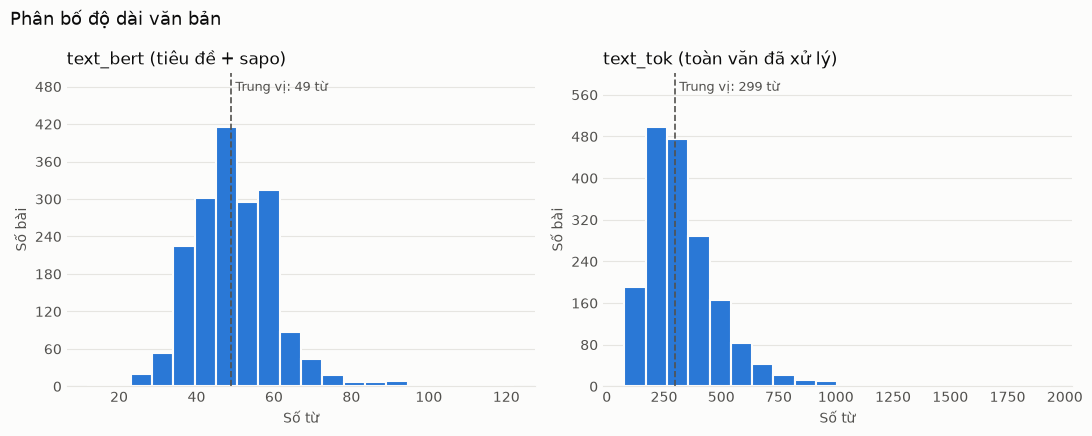

In [7]:
# Hình 2: phân bố độ dài text_bert và text_tok
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), facecolor=SURFACE)
for ax, col, title in [(axes[0], "n_bert", "text_bert (tiêu đề + sapo)"), (axes[1], "n_tok", "text_tok (toàn văn đã xử lý)")]:
    ax.set_facecolor(SURFACE)
    ax.hist(df[col], bins=20, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5)
    med = df[col].median()
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * 1.15)  # chừa chỗ phía trên cho nhãn trung vị
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.axvline(med, color=INK2, linestyle="--", linewidth=1.2)
    ax.text(med, top * 1.12, f" Trung vị: {med:.0f} từ", color=INK2, fontsize=9, va="top", ha="left")
    ax.set_title(title, loc="left", fontsize=12, color=INK)
    ax.set_xlabel("Số từ", color=INK2)
    ax.set_ylabel("Số bài", color=INK2)
    ax.tick_params(colors=INK2, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
fig.suptitle("Phân bố độ dài văn bản", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_do_dai.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.show()

## 4. Từ khóa phổ biến theo chủ đề (kiểm tra nhanh)

Đếm số bài chứa từ đó (document frequency). Nếu danh sách của một chủ đề có từ không liên quan (tên tác giả, "bình_luận", "xem_thêm"...) thì dữ liệu còn chữ thừa: sửa lại bước làm sạch hoặc bổ sung `data/stopwords/vietnamese_stopwords.txt`.

In [8]:
rows = {}
for key, name in TOPICS.items():
    docs = df.loc[df["true_label"] == key, "text_tok"].str.split()
    df_count = Counter(t for doc in docs for t in set(doc))
    rows[name] = ", ".join(w for w, _ in df_count.most_common(10))
pd.set_option("display.max_colwidth", None)  # hiện đủ danh sách từ, không bị cắt
pd.DataFrame({"Top 10 từ (theo số bài chứa)": rows})

,Top 10 từ (theo số bài chứa)
Thời sự,"khu_vực, dân, xây_dựng, đồng, tỉnh, nước, địa_phương, bộ, cấp, xã"
Kinh tế,"doanh_nghiệp, tăng, thị_trường, giảm, đầu_tư, đồng, việt_nam, nước, tỷ, triệu"
Thể thao,"trận, thi_đấu, đội, giải, bóng, giành, trận_đấu, sân, thắng, cầu_thủ"
Giải trí,"khán_giả, diễn, tham_gia, tuổi, bộ, chương_trình, hình_ảnh, nghệ_thuật, phim, cuộc"
Công nghệ,"công_nghệ, dùng, hệ_thống, thiết_bị, ứng_dụng, sản_phẩm, công_ty, dữ_liệu, cung_cấp, xử_lý"
Sức khỏe,"bác_sĩ, bệnh, điều_trị, tình_trạng, giảm, tăng, bệnh_viện, nguy_cơ, sức_khỏe, tuổi"


## 5. Số bài thu thập và bài bị loại

Đọc từ `data/raw/*.jsonl` (máy nào đã crawl mới có; thư mục này không commit). Bài bị loại gồm bài trùng, bài ngắn, bài thừa so với mức cân bằng.

In [9]:
raw_counts = {}
for key in TOPICS:
    path = DATA_RAW / f"{key}.jsonl"
    if path.exists():
        n = 0
        with open(path, encoding="utf-8") as f:
            for line in f:
                try:
                    json.loads(line); n += 1
                except json.JSONDecodeError:
                    pass
        raw_counts[key] = n

if raw_counts:
    collect = pd.DataFrame({
        "Bài thu thập (raw)": pd.Series(raw_counts),
        "Bài giữ lại": counts,
    }).reindex(list(TOPICS))
    collect["Bài bị loại"] = collect["Bài thu thập (raw)"] - collect["Bài giữ lại"]
    collect.index = [TOPICS[k] for k in collect.index]
    collect.loc["Tổng"] = collect.sum()
    display(collect)
else:
    print("Chưa có data/raw/*.jsonl trên máy này, bỏ qua mục này.")

,Bài thu thập (raw),Bài giữ lại,Bài bị loại
Thời sự,325,300,25
Kinh tế,308,300,8
Thể thao,325,300,25
Giải trí,317,300,17
Công nghệ,326,300,26
Sức khỏe,326,300,26
Tổng,1927,1800,127


## 6. Xuất bảng markdown để dán vào `ket_qua/01_du_lieu.md`

Chạy ô dưới, copy kết quả in ra và dán vào các mục tương ứng. Các mục còn lại (nguồn sử dụng, ngày thu thập, nhận xét, dàn ý slide) điền tay.

In [10]:
def to_md(frame, index_name=""):
    # đổi DataFrame thành bảng markdown (không cần thư viện ngoài)
    cols = [index_name] + [str(c) for c in frame.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in frame.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v:,.1f}".rstrip("0").rstrip(".") if isinstance(v, float) else f"{v:,}".replace(",", ".") if isinstance(v, int) else str(v) for v in row]) + " |")
    return "\n".join(lines)

vn = lambda n: f"{n:,}".replace(",", ".")  # 1800 -> 1.800
dates = pd.to_datetime(df["date"])
recent = (dates >= dates.max() - pd.Timedelta(days=11)).mean()  # tỷ lệ bài đăng trong 12 ngày cuối
cnt_text = f"{counts.min()}" if counts.min() == counts.max() else f"{counts.min()} – {counts.max()}"

print("### Mục 1. Tóm tắt\n")
print("| Tiêu chí | Mục tiêu | Kết quả |\n|---|---|---|")
print(f"| Tổng số bài | ~1.800 | {vn(len(df))} |")
print(f"| Số chủ đề | 6 | {df['true_label'].nunique()} |")
print(f"| Số bài mỗi chủ đề | 300 (tối thiểu 200) | {cnt_text} |")
print(f"| Số nguồn báo | 4 | {df['source'].nunique()} |")
print(f"| Ngày đăng bài | | {df['date'].min()} → {df['date'].max()}; {recent:.0%} bài đăng trong 12 ngày cuối |")

if raw_counts:
    print("\n### Mục 3. Kết quả thu thập\n")
    print(to_md(collect.astype(int), "Chủ đề"))

print("\n### Mục 2 (gợi ý). Số bài theo chủ đề × nguồn\n")
print(to_md(table.astype(int), "Chủ đề"))

print("\n### Mục 4. Thống kê mô tả\n")
print("| Chỉ số | `text_bert` | `text_tok` |\n|---|---|---|")
print(f"| Số từ trung bình | {df['n_bert'].mean():.1f} | {df['n_tok'].mean():.1f} |")
print(f"| Số từ nhỏ nhất / lớn nhất | {df['n_bert'].min()} / {df['n_bert'].max()} | {df['n_tok'].min()} / {df['n_tok'].max()} |")
print(f"| Kích thước từ vựng | — | {vn(len(vocab))} |")
print("\nHình: `outputs/figures/eda_so_bai_chu_de.png`, `outputs/figures/eda_do_dai.png`")

### Mục 1. Tóm tắt

| Tiêu chí | Mục tiêu | Kết quả |
|---|---|---|
| Tổng số bài | ~1.800 | 1.800 |
| Số chủ đề | 6 | 6 |
| Số bài mỗi chủ đề | 300 (tối thiểu 200) | 300 |
| Số nguồn báo | 4 | 4 |
| Ngày đăng bài | | 2021-10-06 → 2026-11-20; 82% bài đăng trong 12 ngày cuối |

### Mục 3. Kết quả thu thập

| Chủ đề | Bài thu thập (raw) | Bài giữ lại | Bài bị loại |
|---|---|---|---|
| Thời sự | 325 | 300 | 25 |
| Kinh tế | 308 | 300 | 8 |
| Thể thao | 325 | 300 | 25 |
| Giải trí | 317 | 300 | 17 |
| Công nghệ | 326 | 300 | 26 |
| Sức khỏe | 326 | 300 | 26 |
| Tổng | 1.927 | 1.800 | 127 |

### Mục 2 (gợi ý). Số bài theo chủ đề × nguồn

| Chủ đề | VnExpress | Tuổi Trẻ | Thanh Niên | Dân trí | Tổng |
|---|---|---|---|---|---|
| Thời sự | 108 | 20 | 63 | 109 | 300 |
| Kinh tế | 117 | 15 | 51 | 117 | 300 |
| Thể thao | 107 | 38 | 47 | 108 | 300 |
| Giải trí | 111 | 18 | 59 | 112 | 300 |
| Công nghệ | 107 | 34 | 52 | 107 | 300 |
| Sức khỏe | 108 | 22 | 62 | 108 | 300 |
| Tổng | 658 | 147 | 33